In [1]:
import sys
print(sys.executable)

import torch
print(torch.__version__)

d:\learning\AI\LLM\runnoob_ai\.venv\Scripts\python.exe
2.14.1+cpu


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [13]:
class Value:
    def __init__(self,data, _children=(), _op='',label=''):
        self.data=data
        self.grad=0.0 #初始化梯度为0，假设其不影响变量的改变
        self._backward=lambda:None
        self._prev=set(_children)
        self._op=_op
        self.label=label

    def __repr__(self): 
        return f"Value(data={self.data})"  #打印

    def __add__(self,other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data+other.data, (self,other), '+')
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad
        out._backward=_backward
        return out
    def __mul__(self,other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data*other.data, (self,other), '*')
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        return out

    def __rmul__(self,other):    #other * self 这个东西好神秘啊啊啊啊啊
        return self*other

    def __pow__(self, other):
        assert isinstance(other,(int,float)),"only supporting int/float powers for now"
        out = Value(self.data**other,(self,),f'**({other}')
        def _backward():
            self.grad += other*(self.data**(other-1))*out.grad
        out._backward=_backward
        return out


    def __truediv__(self, other):
        return self * other**-1


    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t, (self,), 'tanh')
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out

    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')
        def _backward():
            self.grad=out.data*out.grad
        out._backward=_backward
        return out

    
    def backward(self):
        tope=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                tope.append(v)
        build_topo(self)
        self.grad=1.0
        for node in reversed(tope):
            node._backward()




关于除法一个更通用的方式：
a/b
a * （1/b）
a * （b ** -1）

减法也有更通用的方式

In [4]:
a=Value(2.0, label='a')
b=Value(4.0)
a/b
a-b

Value(data=-2.0)

In [5]:
import os
import subprocess

graphviz_bin = r"C:\Program Files\Graphviz\bin"
os.environ["PATH"] = graphviz_bin + os.pathsep + os.environ.get("PATH", "")

subprocess.run(["dot", "-V"], check=True)

CompletedProcess(args=['dot', '-V'], returncode=0)

In [6]:
from graphviz import Digraph

def trace(root):
    #builds a set of all nodes and edges in a graph
    nodes,edges = set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
        for child in v._prev:
            edges.add((child, v))
            build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR-left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label=f"{n.label} | data={n.data:.4f} | grad={n.grad:.4f}", shape="record")
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    # and connect this node to it
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

In [7]:
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')

w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')

b=Value(6.8813735870195432,label='b')

x1w1 = x1*w1;x1w1.label= 'x1*w1'
x2w2 = x2*w2;x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n = x1w1x2w2+b;n.label='n'

o=n.tanh();o.label='o'
o.backward()

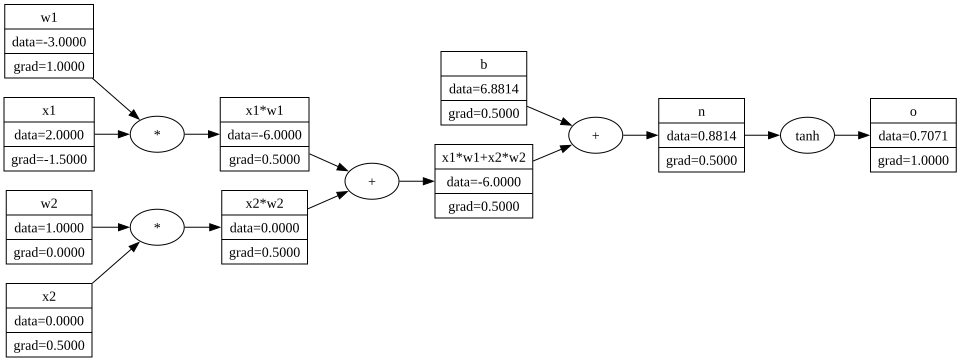

In [8]:
draw_dot(o)

In [14]:
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')

w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')

b=Value(6.8813735870195432,label='b')

x1w1 = x1*w1;x1w1.label= 'x1*w1'
x2w2 = x2*w2;x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n = x1w1x2w2+b;n.label='n'
# ----
#o=n.tanh();o.label='o'
e=(2*n).exp()
o=(e-1)/(e+1)
# ----
o.label='o'
o.backward()

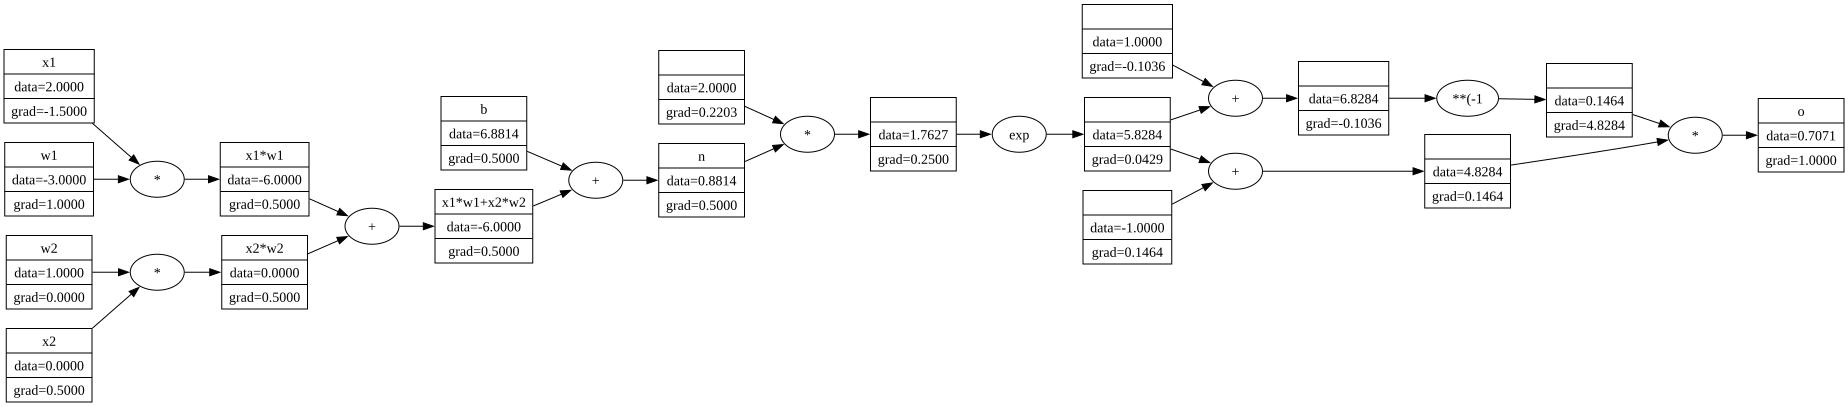

In [15]:
draw_dot(o)

In [16]:
import torch

In [19]:
x1=torch.Tensor([2.0]).double()    ;x1.requires_grad=True
x2=torch.Tensor([0.0]).double() ;x2.requires_grad=True
w1=torch.Tensor([-3.0]).double()    ;w1.requires_grad=True
w2=torch.Tensor([1.0]).double() ;w2.requires_grad=True
b=torch.Tensor([6.8813735870195432]).double()   ;b.requires_grad=True
n=x1*w1+x2*w2+b
o=torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2',x2.grad.item())
print('w2',w2.grad.item())
print('x1',x1.grad.item())
print('w1',w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [20]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [28]:
import random
class Neuron:
    def __init__(self,nin):
        self.w=[Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))
    def __call__(self, x):
        act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
        out =act.tanh()
        return out
class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x): 
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  
#   def parameters(self):
#     return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

x=[2.0,3.0,-1.0]
n=MLP(3,[4,4,1])
n(x)

Value(data=-0.5985748048974369)

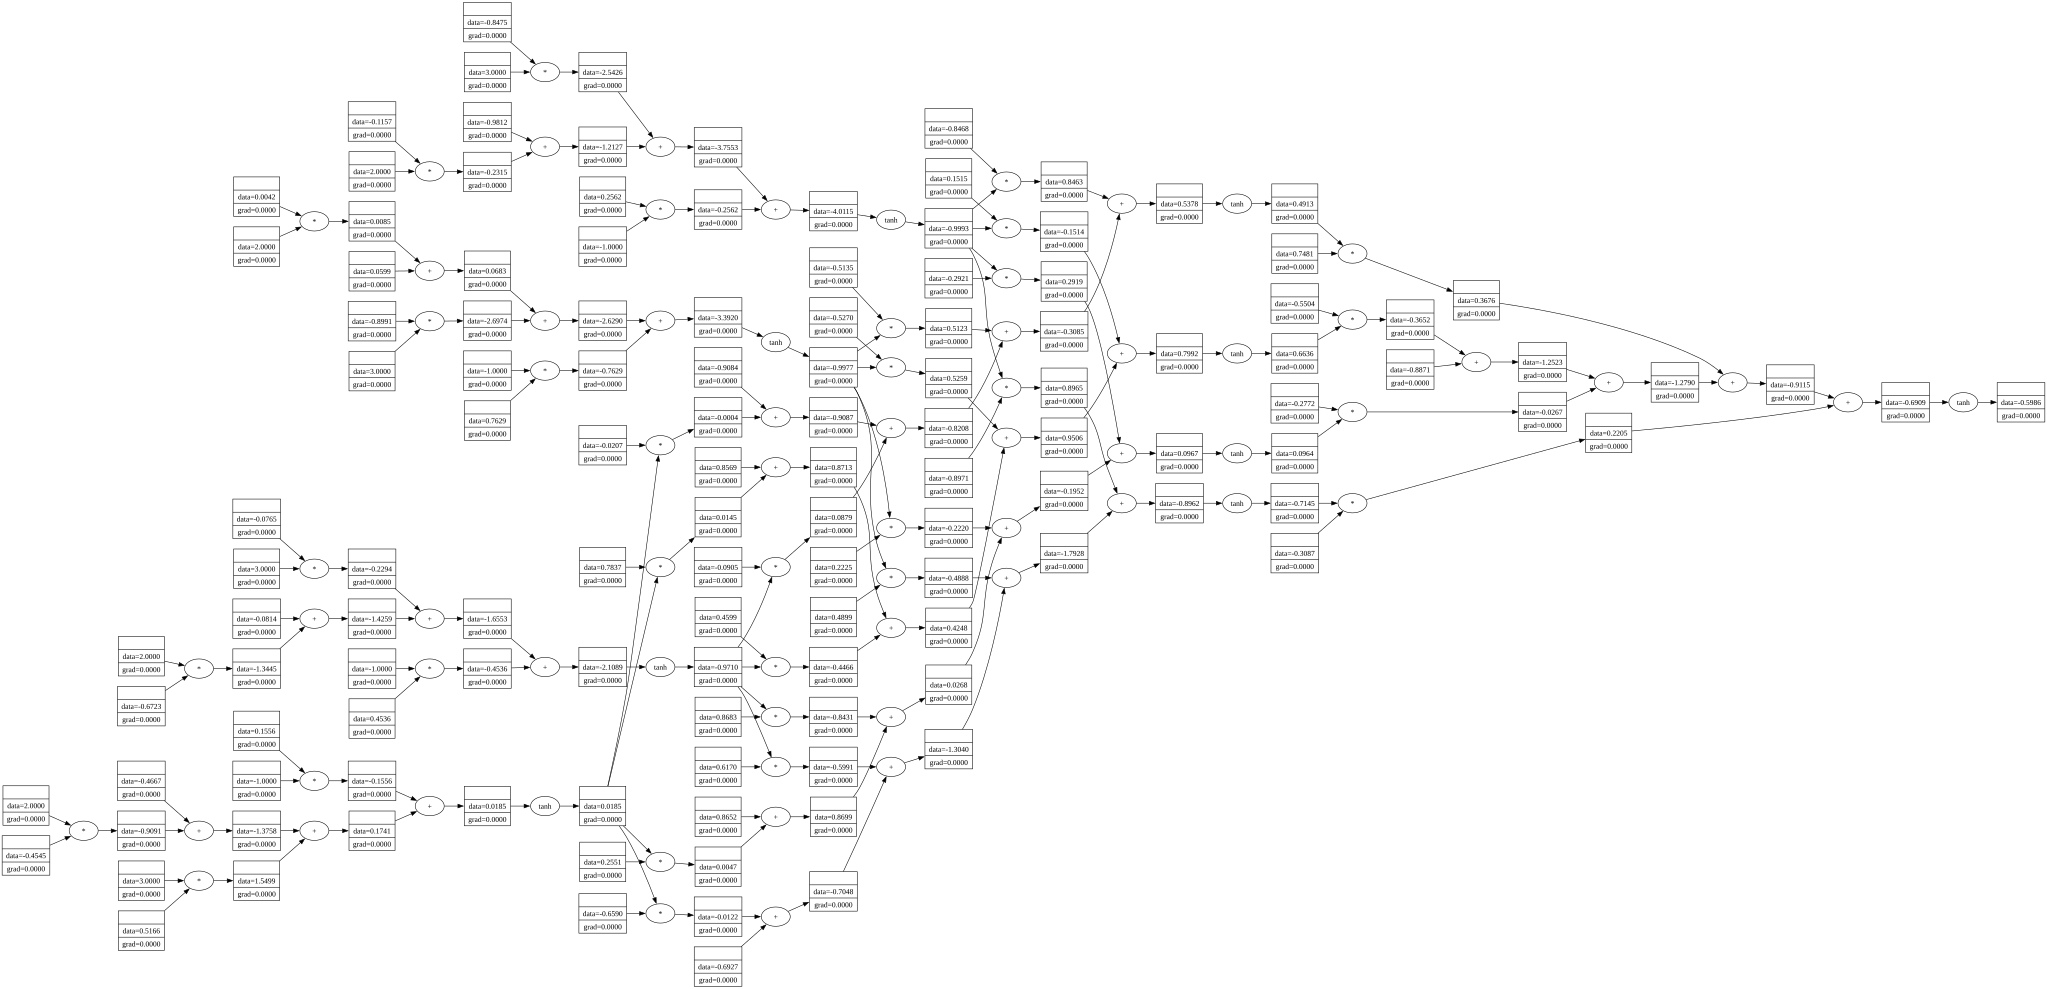

In [29]:
draw_dot(n(x))